<a href="https://colab.research.google.com/github/Berrybanana23/Data_Science_Simulation_Exercises/blob/main/Data_Science_Simulation_Exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Data Science Simulation Exercises
This is a collection of the data science exercises I've completed as part of my 'Data Science for Brain and Behaviour' module.<br>
I'm storing them here so I can look back on what I've done and keep a record of how far I've come!<br>
I will try to keep this updated as the course goes on.<br>
<br>

###CREDITS:
These exercises were adapted by lecturers at the University of Birmingham from the [Berkeley Data Science Course](https://github.com/data-8/data8assets/tree/gh-pages).<br>
All credit goes to them for creating the exercises! Thank you for the help!


---






---


## Three Boys Problem


---


This exercise asked 'in a family of 4 children, how likely is it that 3 would be boys?'.<br>
This exercise introduced me to creating simulations to understand what the data would look like in a 'fair world' where there was an equal chance of getting boys or girls. <br>

First, I created a simple version to fit the brief. Then, because I had experience of Python and knew how to create loops, I made a versatile version which you could plug any values into.<br>


---



**My to-do list:**<br>
Simulate [num1] boys in families of size [num2]<br>

**STEPS:**
- Create empty array for boys_in_fam
- Set counter to 0

- Create loop for length of boys_in_fam
- Simulate family of children
- Count boys (1s)
- Add to boys_in_fam array
- Increase counter by 1

- Logical search - which families have n_boys boys?
- Sum
- Divide total by sample size to find percentage/probability
- Make sure thing returns the right info

In [1]:
# IMPORT PACKAGES
import numpy as np
import matplotlib.pyplot as plt

In [7]:
# VARIABLES
n_boys = 3 #The amount of boys we're looking at the probabilty of having
n_child = 4 #The amount of children in the family
sample_size = 10000 #The number of simulations to run

246/1000 families with 4 children in the sample have 3 boys.
The probabilty of having 3 boys in a family of 4 children is 0.246 or 24.6%.


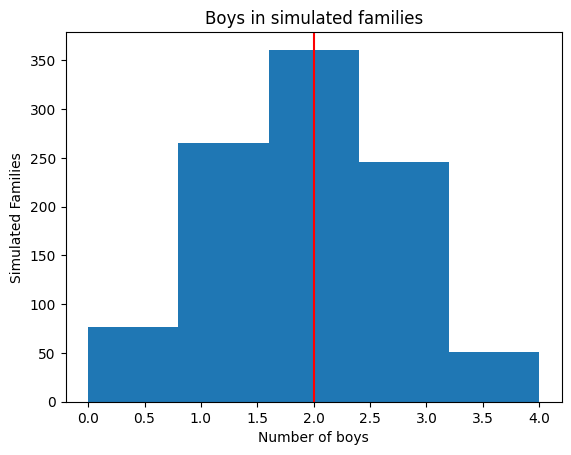

In [14]:
# CREATING A FUNCTION TO MAKE THE SIMULATION VERSATILE

def simulate_family(n_boys, n_child, sample_size):
    n_boys_each_family = np.full(shape=sample_size, fill_value=np.nan)
    #print(n_boys_each_family) #Checking empty array was correct

    for i in range(len(n_boys_each_family)):
        family=np.random.randint(low=0, high=2, size=n_child)
        #print(f"Family {a+1} has {np.sum(family)} boys.") #Show simulated family
        n_boys_each_family[i]= np.sum(family)
        #print(n_boys_each_family) #Checks that overall array is updating.

    fam_w_n_boys=np.sum(n_boys_each_family==n_boys)
    print(f"{fam_w_n_boys}/{sample_size} families with {n_child} children in the sample have {n_boys} boys.")

    prob_n_boys = fam_w_n_boys / sample_size
    plt.hist(n_boys_each_family, bins=5)
    plt.title("Boys in simulated families")
    plt.xlabel("Number of boys")
    plt.ylabel("Simulated Families")
    plt.axvline(2, color="red")

    return(prob_n_boys)


prob_n_boys = simulate_family(n_boys, n_child, sample_size)
print(f"The probabilty of having {n_boys} boys in a family of {n_child} children is {prob_n_boys} or {prob_n_boys*100}%.")



---


---




# Henry VII Version


---

TASK:
Henry VIII had at least 15 children -
- four survived
- 11 were stillborn or died in infancy
- 2 surviving children were boys

How likely is it that 2 of 15 were boys?<br>


**STEPS (need to):**
- Create empty array length of sample size (1000)

- Create loop for length of array/1000 samples
- Simulate each child (0/1 for girl/boy) in 1 version of the family
- Count boys (True-s)
- Add to array
- Increase counter by 1

- Count versions with 2 boys
- Sum

The probability of Henry having 2 boys is 0.00345%.


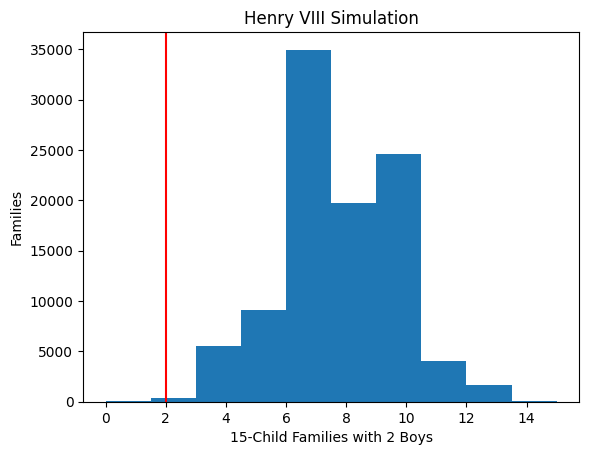

In [15]:
henry_fam = 15 #Henry's 15 kids
boys = 2 #no of boys we're looking for
sample_size = 100000

def henry_simulation(henry_fam, boys, sample_size):
    sample = np.full(shape=sample_size, fill_value=np.nan)

    for i in range(len(sample)):
        family=np.random.randint(0,2,henry_fam)
        sample[i]=np.sum(family)
        #print(i)
        #print(sample)

    plt.hist(sample)
    plt.title('Henry VIII Simulation')
    plt.xlabel('15-Child Families with 2 Boys')
    plt.ylabel('Families')
    plt.axvline(2, color="red") #Plotted at real-world outcome: likelihood of 2 boys occurring by chance in real-world outcome.

    fam_w_boys = np.sum(sample == boys)
    #print(fam_w_boys)
    prob_2_boys = fam_w_boys / sample_size
    #print(prob_2_boys)
    return prob_2_boys

prob_2_boys = henry_simulation(henry_fam, boys, sample_size)
print(f"The probability of Henry having 2 boys is {prob_2_boys}%.")




---


---


## The Swain Jury Exercise


---

In 1965, a Black man called Swain was convicted of sexual assault in Alabama and sentenced to death by an all-white jury. The case was appealed due to the fact that the jury were all white (despite the fact that 26% of eligible jurors in the county were Black). <br>
Our task was to determine if it was statistically fair for 0 of the 12 jurors to be Black, or if discrimination was likely to be at play.

TASK:<br>
Creating a fair jury because we know what that would look like!<br>
26% of population are Black, 74% white. A fair jury will reflect these numbers.<br>

0.26 = p of picking Black jury member<br>
0.74 = p of picking white jury member

2 questions:
- Is it fair that 8/100 empaneled jurors were Black?
- Is if fair that none of those jurors made it to the jury?

STEPS:
- Create empty array length of sample size (1000+)<br>
- Create loop for length of array
- Simulate each jury
- Count Black members of jury
- Add to array<br>
- Count number of Black jurors in sample of juries.
- Sum

There were 3214 Black jurors in a sample of 1000 juries of 12 people.
26.78% of the jurors selected in total were Black.
29/1000 juries had 0 Black jurors in the sample, or 2.9% of the sample.
This makes getting 0 Black jurors a fairly uncommon occurrence (p = 0.03).


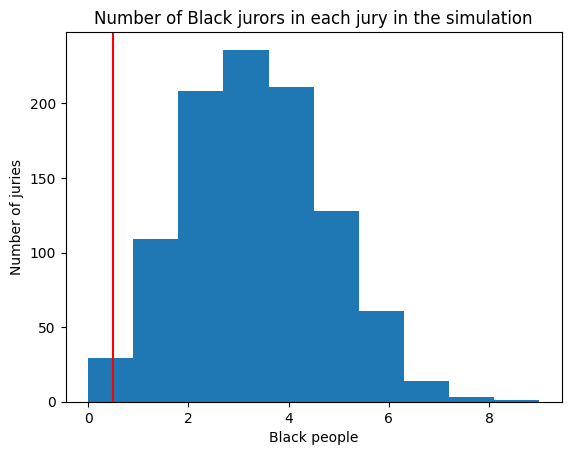

In [10]:
import numpy as np
import matplotlib.pyplot as plt

sample_size = 1000
jury_size = 12
target = 0

def simulate_jury(sample_size, jury_size, target):
    sample = np.full(shape=sample_size, fill_value=np.nan)
    # print(sample)
    # print(range(len(sample)))

    for i in range(len(sample)):
        jury1=np.random.randint(low=0, high=100, size=jury_size)
        black_members = np.sum(jury1 <= 26)
        sample[i] = int(black_members)
        #print('jury1', jury1)
        #print('BM:', black_members)
        #print('i:', i)

    #print('Black jurors in each jury:', sample)
    black_jurors = np.sum(sample)
    no_black_jurors = np.sum(sample == target)

    #PLOTTING DIAGRAM
    plt.hist(sample)
    plt.title('Number of Black jurors in each jury in the simulation')
    plt.xlabel('Black people')
    plt.ylabel('Number of juries')
    plt.axvline(0.5, color="red")

    #DESCRIBING PROBABILITY
    print(f"There were {int(black_jurors)} Black jurors in a sample of {sample_size} juries of {jury_size} people.")
    print(f"{round(black_jurors/(sample_size*jury_size)*100, 2)}% of the jurors selected in total were Black.")
    print(f"{no_black_jurors}/{sample_size} juries had 0 Black jurors in the sample, or {round(no_black_jurors/sample_size*100, 2)}% of the sample.")
    print(f"This makes getting 0 Black jurors a fairly uncommon occurrence (p = {round(no_black_jurors/sample_size, 2)}).")

    return sample

simulation = simulate_jury(sample_size, jury_size, target)



---



---

## The Crooked Euro


---


Is the Euro coin really perfectly balanced and symmetric?
Some researchers [found](https://www.theguardian.com/world/2002/jan/04/euro.eu2) that when the Euro was tossed 250 times, the coin came up heads 139 times and tails 111.
For a fair and balanced coin, the chance of each side should be 0.5 (50%). We expect 50% of the tosses to be heads, or around 125.<br>
Is 139 too high for the coin to be fair?

This task involved simulating coin tosses in a 'fair world' where it really IS a 50% chance of getting either side. If getting 139 heads in this world is unrealistic, we have to question if the coin really IS fair.



In [16]:
# One trial of the coin-tossing problem.
# Toss 150 coins, each with a 50% chance of giving heads (1).
tosses = np.random.randint(0, 2, size=250)
# Count the number of heads.
n_heads = np.sum(tosses)

#print(n_heads)

In [27]:
# Array to store the number of heads on each trial.
counts = np.full(shape=10000, fill_value=np.nan)
for i in range(len(counts)):
    # Each indented statement gets run on every trial
    tosses = np.random.randint(0, 2, size=250)
    n_heads = np.sum(tosses)
    counts[i] = n_heads
p_crooked = np.count_nonzero(counts >= 139) / 10000
print(f"The probability of getting 139 or more heads in 250 coin tosses, if the coin is fair: {p_crooked} or {p_crooked*100}%")

The probability of getting 139 or more heads in 250 coin tosses, if the coin is fair: 0.0454 or 4.54%


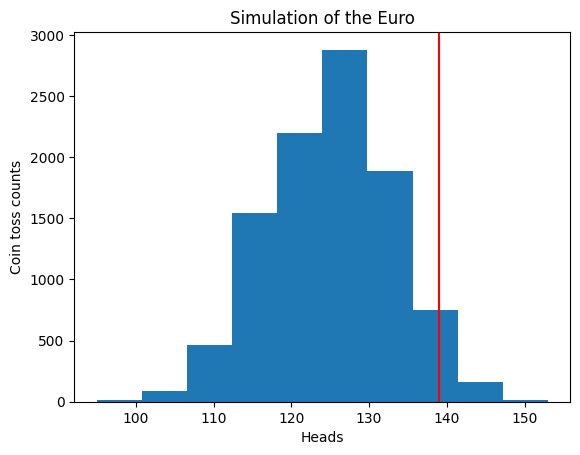

In [28]:
# Plotting the data

plt.hist(counts)
plt.title("Simulation of the Euro")
plt.xlabel("Heads")
plt.ylabel("Coin toss counts")
plt.axvline(139, color="red")